# Fine-Tuning: Last 1 / 2 / 3 Blocks
Requires `finetune_setup.ipynb` to have been run first.

Uses the official BrainOmni `downstream/` recipe:
- AdamW with differential learning rates (pretrained blocks at backbone_lr=1e-5, random head at head_lr=1e-4)
- Warmup-cosine schedule (10% warmup)
- Weight decay 0.05, label smoothing 0.1, gradient clipping
- Caches frozen blocks and only trains the last 1/2/3 blocks (fast)

In [5]:
import os, sys, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/meg_ad_project')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

Device: mps


In [6]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))  # (N, 16, NT, 256)
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
split     = np.load(os.path.join(SAVE_DIR, 'split.npz'))
train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']

print(f'Loaded {len(proj_out1)} subjects | proj_out shape: {proj_out1.shape}')
print(f'Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}')

Loaded 148 subjects | proj_out shape: (148, 16, 160, 256)
Train: 118 | Val: 15 | Test: 15


In [7]:
import math

class CachedMEGDataset(Dataset):
    def __init__(self, indices, cached1, cached2, labels):
        self.indices = indices
        self.cached1 = cached1
        self.cached2 = cached2
        self.labels  = labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        return self.cached1[idx], self.cached2[idx], torch.tensor(self.labels[idx], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=256):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1)
            x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def make_warmup_cosine(optimizer, total_steps, warmup_ratio=0.1, warmup_min=0.1, cos_min=0.1):
    """Linear warmup for the first 10% of steps, then cosine decay to 10% of base LR.
    Mirrors the official BrainOmni WarmupCosineLR."""
    warmup_steps = max(1, int(total_steps * warmup_ratio))
    def lr_lambda(step):
        if step < warmup_steps:
            return warmup_min + (1 - warmup_min) * step / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return cos_min + (1 - cos_min) * 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

def run_finetune(n_frozen, backbone_lr=1e-5, head_lr=1e-4, max_epochs=60, patience=25):
    print(f'\n=== Fine-tuning: last {11 - n_frozen} block(s) unfrozen (N_FROZEN={n_frozen}) '
          f'| backbone_lr={backbone_lr:.0e} head_lr={head_lr:.0e} ===')

    model = BrainOmni(**model_config)
    model.load_state_dict(base_checkpoint, strict=False)
    for param in model.parameters():
        param.requires_grad = False
    model = model.to(device).eval()

    # Cache output of frozen blocks — proj_out1/proj_out2 are already tokenized
    cached1, cached2 = [], []
    with torch.no_grad():
        for i in tqdm(range(len(proj_out1)), desc='Caching', leave=False):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:n_frozen]:
                x1 = block(x1)
                x2 = block(x2)
            cached1.append(x1.squeeze(0).cpu())
            cached2.append(x2.squeeze(0).cpu())

    train_loader = DataLoader(CachedMEGDataset(train_idx, cached1, cached2, labels), batch_size=8, shuffle=True)
    val_loader   = DataLoader(CachedMEGDataset(val_idx,   cached1, cached2, labels), batch_size=8)
    test_loader  = DataLoader(CachedMEGDataset(test_idx,  cached1, cached2, labels), batch_size=8)

    unfrozen = nn.ModuleList(list(model.blocks)[n_frozen:-1])
    for param in unfrozen.parameters():
        param.requires_grad = True
    ft_model  = FinetuneClassifier(unfrozen, hidden_dim=256).to(device)

    # Official BrainOmni recipe: AdamW, differential LR (pretrained blocks small,
    # random head 10x larger), weight decay, warmup-cosine schedule, label smoothing.
    optimizer = torch.optim.AdamW([
        {'params': ft_model.blocks.parameters(), 'lr': backbone_lr, 'weight_decay': 0.05},
        {'params': ft_model.head.parameters(),   'lr': head_lr,     'weight_decay': 0.05},
    ], betas=(0.9, 0.99), eps=1e-6)
    total_steps = max_epochs * len(train_loader)
    scheduler = make_warmup_cosine(optimizer, total_steps)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_val, patience_count, best_weights = 0, 0, None
    train_accs, val_accs, train_losses, val_losses = [], [], [], []

    for epoch in range(max_epochs):
        ft_model.train()
        preds, trues, epoch_loss = [], [], 0.0
        for x1, x2, y in train_loader:
            optimizer.zero_grad()
            out  = ft_model(x1, x2)
            loss = criterion(out, y.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(ft_model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            epoch_loss += loss.item()
            preds.extend(out.argmax(1).cpu().numpy())
            trues.extend(y.numpy())
        train_acc  = accuracy_score(trues, preds)
        train_loss = epoch_loss / len(train_loader)

        ft_model.eval()
        preds, trues, val_loss_sum = [], [], 0.0
        with torch.no_grad():
            for x1, x2, y in val_loader:
                out = ft_model(x1, x2)
                val_loss_sum += criterion(out, y.to(device)).item()
                preds.extend(out.argmax(1).cpu().numpy())
                trues.extend(y.numpy())
        val_acc  = accuracy_score(trues, preds)
        val_loss = val_loss_sum / len(val_loader)

        train_accs.append(train_acc)
        val_accs.append(val_acc)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        current_lr = optimizer.param_groups[0]['lr']
        print(f'  Epoch {epoch+1:03d} | Train: {train_acc:.3f} (loss {train_loss:.4f}) | Val: {val_acc:.3f} (loss {val_loss:.4f}) | bb_lr: {current_lr:.2e}')

        if val_acc > best_val:
            best_val = val_acc
            best_weights = {k: v.clone() for k, v in ft_model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    ft_model.load_state_dict(best_weights)
    ft_model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x1, x2, y in test_loader:
            out = ft_model(x1, x2)
            preds.extend(out.argmax(1).cpu().numpy())
            trues.extend(y.numpy())
    test_acc = accuracy_score(trues, preds)
    print(f'  Best val: {best_val:.3f} | Test acc: {test_acc:.3f}')

    return {
        'n_unfrozen': 11 - n_frozen, 'n_frozen': n_frozen,
        'best_val': best_val, 'test_acc': test_acc,
        'train_accs': train_accs, 'val_accs': val_accs,
        'train_losses': train_losses, 'val_losses': val_losses,
        'best_weights': best_weights
    }

print('Helpers ready.')

Helpers ready.


In [8]:
# Run all 3 experiments — fast (caches frozen blocks, trains only last 1/2/3)
ft_results = {}
for n_frozen in [10, 9, 8]:
    ft_results[n_frozen] = run_finetune(n_frozen)


=== Fine-tuning: last 1 block(s) unfrozen (N_FROZEN=10) | backbone_lr=1e-05 head_lr=1e-04 ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.475 (loss 0.6957) | Val: 0.467 (loss 0.6954) | bb_lr: 2.50e-06
  Epoch 002 | Train: 0.475 (loss 0.6928) | Val: 0.467 (loss 0.6930) | bb_lr: 4.00e-06
  Epoch 003 | Train: 0.585 (loss 0.6893) | Val: 0.667 (loss 0.6909) | bb_lr: 5.50e-06
  Epoch 004 | Train: 0.653 (loss 0.6852) | Val: 0.467 (loss 0.6883) | bb_lr: 7.00e-06
  Epoch 005 | Train: 0.788 (loss 0.6779) | Val: 0.467 (loss 0.6857) | bb_lr: 8.50e-06
  Epoch 006 | Train: 0.729 (loss 0.6708) | Val: 0.533 (loss 0.6811) | bb_lr: 1.00e-05
  Epoch 007 | Train: 0.780 (loss 0.6612) | Val: 0.533 (loss 0.6759) | bb_lr: 9.99e-06
  Epoch 008 | Train: 0.771 (loss 0.6494) | Val: 0.600 (loss 0.6718) | bb_lr: 9.97e-06
  Epoch 009 | Train: 0.788 (loss 0.6343) | Val: 0.533 (loss 0.6664) | bb_lr: 9.93e-06
  Epoch 010 | Train: 0.797 (loss 0.6178) | Val: 0.533 (loss 0.6605) | bb_lr: 9.88e-06
  Epoch 011 | Train: 0.847 (loss 0.5970) | Val: 0.667 (loss 0.6552) | bb_lr: 9.81e-06
  Epoch 012 | Train: 0.788 (loss 0.5787) | Val: 0.600 

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.508 (loss 0.6928) | Val: 0.533 (loss 0.6916) | bb_lr: 2.50e-06
  Epoch 002 | Train: 0.534 (loss 0.6898) | Val: 0.533 (loss 0.6905) | bb_lr: 4.00e-06
  Epoch 003 | Train: 0.525 (loss 0.6875) | Val: 0.533 (loss 0.6885) | bb_lr: 5.50e-06
  Epoch 004 | Train: 0.568 (loss 0.6854) | Val: 0.533 (loss 0.6862) | bb_lr: 7.00e-06
  Epoch 005 | Train: 0.593 (loss 0.6772) | Val: 0.533 (loss 0.6832) | bb_lr: 8.50e-06
  Epoch 006 | Train: 0.695 (loss 0.6687) | Val: 0.533 (loss 0.6783) | bb_lr: 1.00e-05
  Epoch 007 | Train: 0.695 (loss 0.6565) | Val: 0.600 (loss 0.6690) | bb_lr: 9.99e-06
  Epoch 008 | Train: 0.780 (loss 0.6357) | Val: 0.667 (loss 0.6598) | bb_lr: 9.97e-06
  Epoch 009 | Train: 0.780 (loss 0.6084) | Val: 0.667 (loss 0.6501) | bb_lr: 9.93e-06
  Epoch 010 | Train: 0.814 (loss 0.5700) | Val: 0.667 (loss 0.6416) | bb_lr: 9.88e-06
  Epoch 011 | Train: 0.788 (loss 0.5436) | Val: 0.667 (loss 0.6386) | bb_lr: 9.81e-06
  Epoch 012 | Train: 0.822 (loss 0.5038) | Val: 0.667 

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.449 (loss 0.6954) | Val: 0.467 (loss 0.6930) | bb_lr: 2.50e-06
  Epoch 002 | Train: 0.593 (loss 0.6904) | Val: 0.600 (loss 0.6911) | bb_lr: 4.00e-06
  Epoch 003 | Train: 0.661 (loss 0.6886) | Val: 0.533 (loss 0.6890) | bb_lr: 5.50e-06
  Epoch 004 | Train: 0.712 (loss 0.6820) | Val: 0.533 (loss 0.6848) | bb_lr: 7.00e-06
  Epoch 005 | Train: 0.737 (loss 0.6728) | Val: 0.533 (loss 0.6783) | bb_lr: 8.50e-06
  Epoch 006 | Train: 0.771 (loss 0.6521) | Val: 0.600 (loss 0.6641) | bb_lr: 1.00e-05
  Epoch 007 | Train: 0.746 (loss 0.6246) | Val: 0.533 (loss 0.6437) | bb_lr: 9.99e-06
  Epoch 008 | Train: 0.788 (loss 0.5883) | Val: 0.600 (loss 0.6274) | bb_lr: 9.97e-06
  Epoch 009 | Train: 0.797 (loss 0.5362) | Val: 0.533 (loss 0.6112) | bb_lr: 9.93e-06
  Epoch 010 | Train: 0.831 (loss 0.5031) | Val: 0.667 (loss 0.5994) | bb_lr: 9.88e-06
  Epoch 011 | Train: 0.814 (loss 0.4820) | Val: 0.667 (loss 0.5931) | bb_lr: 9.81e-06
  Epoch 012 | Train: 0.856 (loss 0.4802) | Val: 0.733 

In [9]:
print('\n=== Fine-Tuning Comparison ===')
print(f'{"Unfrozen blocks":<20} {"Best Val":<12} {"Test Acc"}')
print('-' * 44)
for n_frozen, res in ft_results.items():
    label = f'Last {res["n_unfrozen"]} block(s)'
    print(f'{label:<20} {res["best_val"]:<12.3f} {res["test_acc"]:.3f}')


=== Fine-Tuning Comparison ===
Unfrozen blocks      Best Val     Test Acc
--------------------------------------------
Last 1 block(s)      0.667        0.733
Last 2 block(s)      0.733        0.800
Last 3 block(s)      0.733        0.867


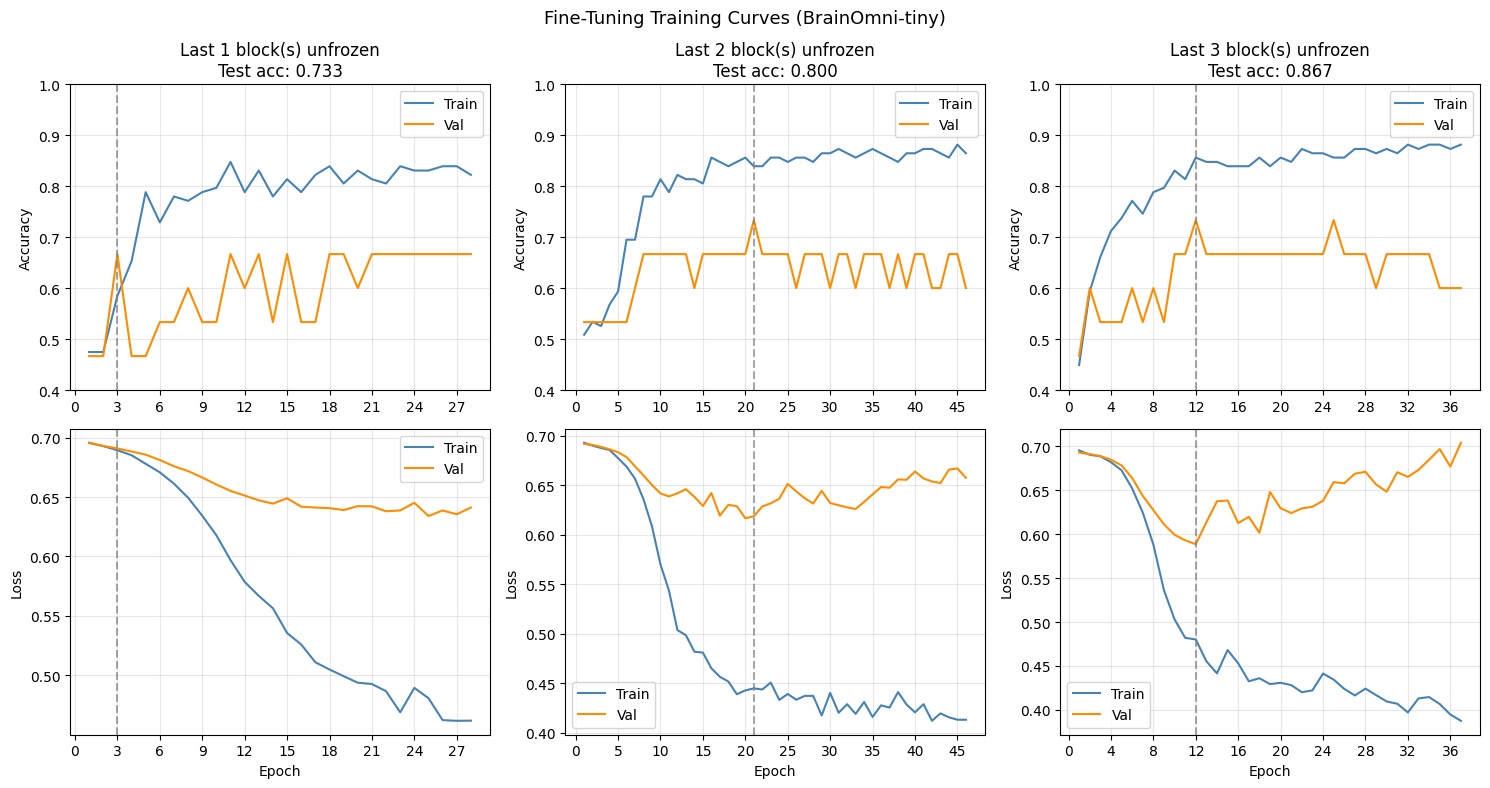

Saved finetune_convergence_curves.png


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (n_frozen, res) in enumerate(ft_results.items()):
    epochs = range(1, len(res['train_accs']) + 1)
    best_ep = int(np.argmax(res['val_accs'])) + 1

    # Accuracy row
    ax = axes[0, col]
    ax.plot(epochs, res['train_accs'], '-', label='Train', color='steelblue')
    ax.plot(epochs, res['val_accs'],   '-', label='Val',   color='darkorange')
    ax.axvline(best_ep, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f'Last {res["n_unfrozen"]} block(s) unfrozen\nTest acc: {res["test_acc"]:.3f}')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0.4, 1.0)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend()
    ax.grid(alpha=0.3)

    # Loss row
    ax = axes[1, col]
    ax.plot(epochs, res['train_losses'], '-', label='Train', color='steelblue')
    ax.plot(epochs, res['val_losses'],   '-', label='Val',   color='darkorange')
    ax.axvline(best_ep, color='gray', linestyle='--', alpha=0.7)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend()
    ax.grid(alpha=0.3)

axes[0, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylabel('Loss')
fig.suptitle('Fine-Tuning Training Curves (BrainOmni-tiny)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_convergence_curves.png'), dpi=150)
plt.show()
print('Saved finetune_convergence_curves.png')

In [11]:
# Save ft_results to disk so finetune_lr_cv.ipynb can load them
torch.save(ft_results, os.path.join(SAVE_DIR, 'ft_results.pt'))
print('Saved ft_results to', SAVE_DIR)

Saved ft_results to ../data/preprocessed
